In [121]:
import Plots
include("FI_curve_compute.jl")
include("RDP.jl")

Main.RDP

In [2]:
k_l = 0.7; k_m = 2.0; k_r = 0.2;

sat_func(x) = x <= -1 ? k_l*x + k_l - k_m : (x >= 1 ? k_r*x - k_r + k_m : k_m*x)

a = -1.0;
b = 1.0;
v_minus = -1 -2*(k_m -1)/(1-k_l);
v_plus = 1 + 2*(k_m - 1)/(1-k_r);

act_sat = ActivationFunction(sat_func, a, b, v_minus, v_plus)

T_sat(u) = (1-k_l)*log1p((2*(k_m - 1))/((1-k_l)*(1+u))) + (1-k_r)*log1p((2*(k_m - 1))/((1-k_r)*(1-u))) 

T_sat (generic function with 1 method)

In [15]:
k = 2; m_l = 0.6; m_r = 1.2;

smooth_func(x) = x <= 0 ? k*x/(1 - k*(x)/m_l) : k*x/(1 + k*(x)/m_r)

a = -m_l*(sqrt(k) - 1)/k;
b = m_r*(sqrt(k) - 1)/k;
S_l = k + 1 + (m_r/m_l)*(sqrt(k) - 1)^2;
S_r = k + 1 + (m_l/m_r)*(sqrt(k) - 1)^2;
W_l = (S_l + sqrt(S_l^2 - 4*k))/2;
W_r = (S_r + sqrt(S_r^2 - 4*k))/2; 
v_minus = -m_l*(W_l - 1)/k; 
v_plus = m_r*(W_r - 1)/k;

act_smooth = ActivationFunction(smooth_func, a, b, v_minus, v_plus)

h(x) = iszero(x) ? zero(x) : x*log(x)                        # x log x, h(0) = 0
l(x) = abs(x) < 1e-3 ? 1/2 + x/3 + x^2/4 + x^3/5 + x^4/6 : (-log1p(-x) - x)/x^2  # (-log(1-x) - x)/x^2, ℓ(0) = 1/2

function Qfunc(W, w, k)
    s = sqrt(k)
    if w > s/2      # near the edge w = √k
        return (1 - k/w^2)*log(W - w) + (w + s)/w^2*h(max(s - w, 0.0)) + k/w^2*log(W/s) + k/w*(1/s - 1/W)
    else            # near w = 0
        return log((W - w)/(s - w)) - l(w/s) + k/W^2*l(w/W)
    end
end

T_smooth(u) = (Qfunc(W_l, 1 - k*u/m_l, k) + Qfunc(W_r, 1 + k*u/m_r, k))

T_smooth (generic function with 1 method)

In [ ]:
# sat_inputs_theory = collect(range(act_sat.a, act_sat.b, length=1000))
# sat_curve_theory = T_sat.(sat_inputs_theory)
# sat_curve_theory = 1.0 ./ sat_curve_theory

# smooth_inputs_theory = collect(range(act_smooth.a, act_smooth.b, length=1000))
# smooth_curve_theory = T_smooth.(smooth_inputs_theory)
# smooth_curve_theory = 1.0 ./ smooth_curve_theory

smooth_curve, smooth_inputs = ComputeUnitlessFICurve(act_smooth)
sat_curve, sat_inputs = ComputeUnitlessFICurve(act_sat)

smooth_xlims = (1.5*act_smooth.a-0.5*act_smooth.b, 1.5*act_smooth.b-0.5*act_smooth.a)
sat_xlims = (1.5*act_sat.a-0.5*act_sat.b, 1.5*act_sat.b-0.5*act_sat.a)

sat_inputs = [act_sat.a, sat_inputs..., act_sat.b]
sat_curve = [0.0, sat_curve..., 0.0]

smooth_curve_sim, smooth_inputs_sim = ComputeUnitlessFICurveSim2(act_smooth; period_mul=20, regultimescale=10^-8, first_spike_index=3)
sat_curve_sim, sat_inputs_sim = ComputeUnitlessFICurveSim2(act_sat; period_mul=20, regultimescale=10^-8, first_spike_index=3)

([0.08311878384596615, 0.5771499222060573, 0.625633103366297, 0.6392999210707436, 0.6309370404402115, 0.6044481828238623, 0.5605243192761796, 0.49697269655224585, 0.40455292240247664, 0.033324607531296076], [-0.9999999999999998, -0.7777777777777776, -0.5555555555555555, -0.33333333333333326, -0.11111111111111109, 0.11111111111111109, 0.33333333333333326, 0.5555555555555555, 0.7777777777777776, 0.9999999999999998])

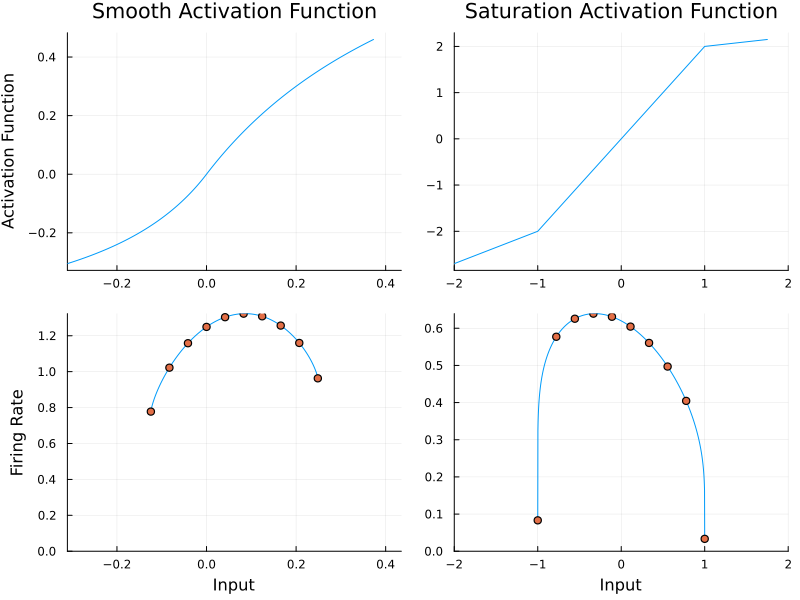

In [165]:
# 4 panel Square plot with activation function above and F-I curve below

smooth_sample_inputs = range(1.5*act_smooth.a-0.5*act_smooth.b, 1.25*act_smooth.b-0.5*act_smooth.a, length=1000)
sat_sample_inputs = range(1.5*act_sat.a-0.5*act_sat.b, 1.25*act_sat.b-0.5*act_sat.a, length=1000)
p1 = Plots.plot(smooth_sample_inputs, smooth_func.(smooth_sample_inputs), label="", ylabel="Activation Function", title="Smooth Activation Function", xlims=smooth_xlims)
p2 = Plots.plot(sat_sample_inputs, sat_func.(sat_sample_inputs), label="", title="Saturation Activation Function", xlims=sat_xlims)
p3 = Plots.plot(smooth_inputs, smooth_curve, label="", xlabel="Input", ylabel="Firing Rate", xlims=smooth_xlims, ylims=(0, Inf))
#p3 = Plots.plot!(p3, smooth_inputs_theory, smooth_curve_theory, color=:black, lw=2, linestyle=:dashdotdot, label="")
#p3 = Plots.scatter!(p3, smooth_inputs[[1, end]], smooth_curve[[1, end]], label="", marker=:xcross, color=:blue, ms=6)
p3 = Plots.scatter!(p3, smooth_inputs_sim, smooth_curve_sim, label="")
p4 = Plots.plot(sat_inputs, sat_curve, label="", xlabel="Input", xlims=sat_xlims, ylims=(0,Inf))
#p4 = Plots.plot!(p4, sat_inputs_theory, sat_curve_theory, color=:black, lw=2, linestyle=:dashdotdot, label="")
#p4 = Plots.scatter!(p4, sat_inputs[[1, end]], sat_curve[[1, end]], label="", marker=:xcross, color=:blue, ms=6)
p4 = Plots.scatter!(p4, sat_inputs_sim, sat_curve_sim, label="")

p = Plots.plot(p1, p2, p3, p4, layout=(2,2), size=(800,600))

In [48]:
import CSV

CSV.write("smooth_act.csv", (x=smooth_sample_inputs, y=smooth_func.(smooth_sample_inputs)))
CSV.write("smooth_FI_formula.csv", (x=smooth_inputs, y=smooth_curve./2))
CSV.write("smooth_FI_sim.csv", (x=smooth_inputs_sim, y=smooth_curve_sim./2))
# CSV.write("smooth_FI_theory.csv", (x=smooth_inputs_theory, y=smooth_curve_theory./2))
CSV.write("sat_act.csv", (x=sat_sample_inputs, y=sat_func.(sat_sample_inputs)))
CSV.write("sat_FI_formula.csv", (x=sat_inputs, y=sat_curve))
CSV.write("sat_FI_sim.csv", (x=sat_inputs_sim, y=sat_curve_sim))
# CSV.write("sat_FI_theory.csv", (x=sat_inputs_theory, y=sat_curve_theory))

"sat_FI_sim.csv"

In [4]:
using BenchmarkTools
b_sat = @benchmarkable ComputeUnitlessFICurve(act_sat);
b_smooth = @benchmarkable ComputeUnitlessFICurve(act_smooth);
b_sat_sim = @benchmarkable ComputeUnitlessFICurveSim(act_sat; period_mul=20, regultimescale=10^-8, first_spike_index=3);
b_smooth_sim = @benchmarkable ComputeUnitlessFICurveSim(act_smooth; period_mul=20, regultimescale=10^-8, first_spike_index=3);

In [5]:
run(b_sat, samples=100,seconds=100,evals=3)

BenchmarkTools.Trial: 100 samples with 3 evaluations per sample.
 Range (min … max):  77.778 ms … 121.679 ms  ┊ GC (min … max): 4.03% … 4.22%
 Time  (median):     87.271 ms               ┊ GC (median):    4.42%
 Time  (mean ± σ):   89.310 ms ±   8.607 ms  ┊ GC (mean ± σ):  4.49% ± 0.51%

   ▂   ▂▄██ ▂▂▂▂      ▄  ▄                                      
  ▆█▄▆█████▆███████▄█▁██▆█▁█▄▄█▄▄▁▄▄▄▁▁▆▁▁▁▁▁▁▁▁▁▄▁▁▄▁▁▁▁▁▁▁▁▄ ▄
  77.8 ms         Histogram: frequency by time          121 ms <

 Memory estimate: 57.73 MiB, allocs estimate: 3700801.

In [6]:
run(b_smooth, samples=100, seconds=100, evals=3)

BenchmarkTools.Trial: 100 samples with 3 evaluations per sample.
 Range (min … max):  66.341 ms … 94.505 ms  ┊ GC (min … max): 4.45% … 5.06%
 Time  (median):     73.817 ms              ┊ GC (median):    4.65%
 Time  (mean ± σ):   75.138 ms ±  5.818 ms  ┊ GC (mean ± σ):  4.60% ± 0.60%

    ▂           ▅   █                                          
  ▅▅█▅▅▄▇▅▇▄▅▅▁▄█▅▅▇█▄▇▅▅▅▅▅▄▄▅█▅▅▅▄█▄▄▄▁▄▁▄▄▄▄▄▄▄▁▅▁▁▁▄▁▁▁▁▄ ▄
  66.3 ms         Histogram: frequency by time          90 ms <

 Memory estimate: 51.76 MiB, allocs estimate: 3329404.

In [7]:
run(b_sat_sim, samples=100, seconds=100, evals=3)

BenchmarkTools.Trial: 100 samples with 3 evaluations per sample.
 Range (min … max):  133.611 ms … 258.148 ms  ┊ GC (min … max): 5.33% … 43.68%
 Time  (median):     147.577 ms               ┊ GC (median):    5.56%
 Time  (mean ± σ):   156.432 ms ±  25.398 ms  ┊ GC (mean ± σ):  9.03% ±  8.71%

   ▃▃█▅██▃  ▃ ▃                                                  
  ▅███████▅██▇█▅▅▄▅▄▄▁▄▄▄▁▅▄▁▄▄▁▁▁▁▁▄▁▁▁▁▁▁▁▁▄▁▁▁▁▁▄▁▄▁▄▁▄▁▁▁▁▄ ▄
  134 ms           Histogram: frequency by time          248 ms <

 Memory estimate: 68.00 MiB, allocs estimate: 3724831.

In [8]:
run(b_smooth_sim, samples=100, seconds=100, evals=3)

BenchmarkTools.Trial: 100 samples with 3 evaluations per sample.
 Range (min … max):  159.827 ms … 304.003 ms  ┊ GC (min … max): 5.13% … 32.54%
 Time  (median):     180.099 ms               ┊ GC (median):    5.69%
 Time  (mean ± σ):   191.392 ms ±  31.458 ms  ┊ GC (mean ± σ):  9.61% ±  8.50%

     ▂▂  █▄▃                                                     
  ▅▃▆███████▇▇▆▇▅▆▆▆▅▃▁▃▁▁▆▁▃▁▁▁▁▁▃▃▁▁▁▁▁▁▁▁▁▁▁▁▃▅▁▁▁▅▃▁▁▁▃▁▁▃▃ ▃
  160 ms           Histogram: frequency by time          290 ms <

 Memory estimate: 87.51 MiB, allocs estimate: 4708490.

In [131]:
func(x) = tanh(2x)

zerofindargs=(xatol=10-7, xrtol=10^-7, atol=10-7, rtol=10^-7)
act = ActivationFunction(func, -atanh(sqrt(0.5))/2, atanh(sqrt(0.5))/2; zerofindargs=zerofindargs)

ActivationFunction(Main.func, -0.4406867935097715, 0.4406867935097715, -1.1876182059423073, 1.1876182059423073)

In [132]:
eval_points = collect(range(act.a*(1+sign(act.a)*eps(Float64)), act.b*(1-sign(act.b)*eps(Float64)), length=1000))

periodsLeft = zeros(length(eval_points))
periodsRight = zeros(length(eval_points))
periods = zeros(length(eval_points))
for (i, u) in enumerate(eval_points)
    periodsLeft[i] = ComputeUnitlessLeftPeriod(act, u)
    periodsRight[i] = ComputeUnitlessRightPeriod(act, u)
    periods[i] = ComputeUnitlessPeriod(act, u)
end

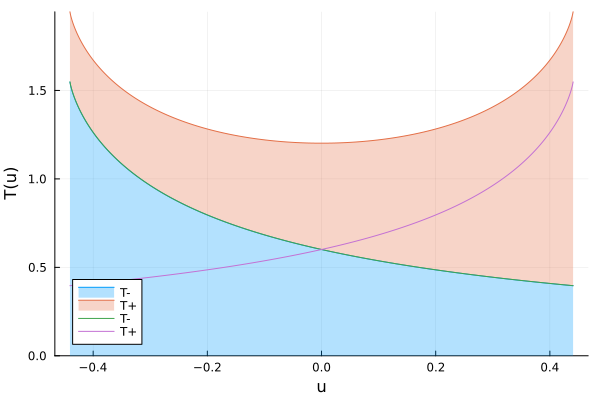

In [144]:
Plots.plot(eval_points, periodsLeft, ylims=(0, Inf), fillrange=0, fillalpha=0.3, label="T-", xlabel="u", ylabel="T(u)")
Plots.plot!(eval_points, periods, ylims=(0, Inf), fillrange=periodsLeft, fillalpha=0.3, label="T+")
Plots.plot!(eval_points, periodsLeft, ylims=(0, Inf), label="T-")
Plots.plot!(eval_points, periodsRight, ylims=(0, Inf), label="T+")

In [145]:
import CSV

CSV.write("period.csv", (x=eval_points, full=periods, left=periodsLeft, right=periodsRight))

"period.csv"

In [175]:
sol_low, spikes_low = SimulateNeuron(act, -0.4; tspan=(0, 8.5), regultimescale=10^-8)
sol_high, spikes_high = SimulateNeuron(act, -0.1; tspan=(0, 8.5), regultimescale=10^-8)

([-0.1116673174820021 -0.11363766254472837 … -0.031460284772691756 -0.09295398386287385; -0.8141524997260394 -0.8113883498373466 … -0.9191768509035589 -0.8398751590165561], [[0.2737454603822153, 1.4917045021487518, 2.7096765762157156, 3.9276355314303513, 5.1455931141648, 6.363560828900928, 7.581524796796775], [0.809665128763137, 2.0276266205238276, 3.2455982794492213, 4.463555878342753, 5.681516154127726, 6.899485538399794, 8.117452972549374]])

In [182]:
output(u, t) = act.func(u[2])

tsol_low, ysol_low = RDP.rdp_sol(sol_low; idxs=output, figsize=(900, 300), shared_ylims=false, dense=200_000, tol=0.1)
tsol_high, ysol_high = RDP.rdp_sol(sol_high; idxs=output, figsize=(900, 300), shared_ylims=false, dense=200_000, tol=0.1)

([0.0, 0.053677768388841945, 0.10195800979004895, 0.14560572802864014, 0.18130590652953266, 0.21488107440537202, 0.23664118320591604, 0.24795297799126798, 0.25661628308141543, 0.26894134470672354  …  8.10967562578861, 8.115647571734682, 8.117328086640434, 8.117452972549374, 8.117452972549374, 8.117453168185113, 8.228976144880724, 8.328851644258222, 8.41920709603548, 8.5], [-0.9258198172080415, -0.9087727080195698, -0.889855006542271, -0.8686391718137272, -0.8469898235176117, -0.8210207808666963, -0.7983783536761693, -0.7842371233347357, -0.7704178866719413, -0.7411602440760781  …  0.7601442485819859, 0.7334405434306193, 0.7139367176717675, 3.657647894714104e-8, 3.657647894714104e-8, -0.9867841989871092, -0.9778545445540003, -0.9660205065428671, -0.951005902327211, -0.932829144829549])

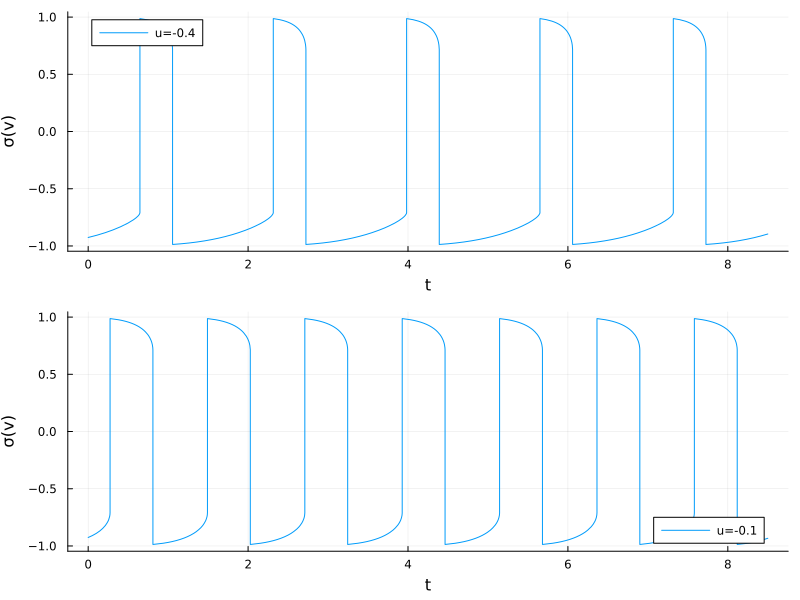

In [185]:
p1 = Plots.plot(tsol_low, ysol_low, label="u=-0.4", ylabel="σ(v)", xlabel="t")
p2 = Plots.plot(tsol_high, ysol_high, label="u=-0.1", ylabel="σ(v)", xlabel="t")
p = Plots.plot(p1, p2, layout=(2, 1), size=(800, 600))

In [184]:
import CSV

CSV.write("period_neuron_u04.csv", (x=tsol_low, y=ysol_low))
CSV.write("period_neuron_u01.csv", (x=tsol_high, y=ysol_high))

"period_neuron_u01.csv"